In [16]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
os.makedirs("images", exist_ok=True)

train = pd.read_csv("data/train.csv", parse_dates=["Date"])
stores = pd.read_csv("data/stores.csv")
features = pd.read_csv("data/features.csv", parse_dates=["Date"])

df = train.merge(stores, on="Store", how="left")
df = df.merge(features[["Store", "Date", "Temperature", "Fuel_Price", "CPI", "Unemployment"]],
              on=["Store", "Date"], how="left")
df["Month"] = df["Date"].dt.to_period("M")

monthly = (df.groupby("Month")
             .agg(total_sales=("Weekly_Sales", "sum"), n_weeks=("Date", "nunique"))
             .reset_index())
monthly["avg_weekly_sales"] = monthly["total_sales"] / monthly["n_weeks"]
monthly["monthly_equiv"] = monthly["avg_weekly_sales"] * 52 / 12
monthly["month_start"] = monthly["Month"].dt.to_timestamp()

m = monthly.set_index("month_start").copy()
m["ma3"] = m["monthly_equiv"].rolling(3).mean()
m["ma12"] = m["monthly_equiv"].rolling(12, center=True).mean()
m["yoy_pct"] = m["monthly_equiv"].pct_change(12) * 100
m["month_num"] = m.index.month
print(df.shape, monthly.shape)

(421570, 12) (33, 6)


In [2]:
train = pd.read_csv("data/train.csv", parse_dates=["Date"])
stores = pd.read_csv("data/stores.csv")
features = pd.read_csv("data/features.csv", parse_dates=["Date"])

print(train.shape, stores.shape, features.shape)
print(train.dtypes)

(421570, 5) (45, 3) (8190, 12)
Store                    int64
Dept                     int64
Date            datetime64[us]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object


In [3]:
print("date range:", train["Date"].min().date(), "to", train["Date"].max().date())
print("stores:", train["Store"].nunique(),
      "| departments:", train["Dept"].nunique(),
      "| weeks:", train["Date"].nunique())

print("duplicates on Store+Dept+Date:", train.duplicated(["Store", "Dept", "Date"]).sum())
print("negative sales rows:", (train["Weekly_Sales"] < 0).sum(),
      "| zero sales rows:", (train["Weekly_Sales"] == 0).sum())

print("\nweekday of each date (4 = Friday):")
print(train["Date"].dt.dayofweek.value_counts())

print("\nWeekly_Sales summary:")
print(train["Weekly_Sales"].describe().round(0))

date range: 2010-02-05 to 2012-10-26
stores: 45 | departments: 81 | weeks: 143
duplicates on Store+Dept+Date: 0
negative sales rows: 1285 | zero sales rows: 73

weekday of each date (4 = Friday):
Date
4    421570
Name: count, dtype: int64

Weekly_Sales summary:
count    421570.0
mean      15981.0
std       22711.0
min       -4989.0
25%        2080.0
50%        7612.0
75%       20206.0
max      693099.0
Name: Weekly_Sales, dtype: float64


In [4]:
print(stores["Type"].value_counts())
print(stores.groupby("Type")["Size"].agg(["count", "min", "max"]))

df = train.merge(stores, on="Store", how="left")
print("\nrows before / after merge:", len(train), "/", len(df))
print("rows with no store Type:", df["Type"].isnull().sum())

Type
A    22
B    17
C     6
Name: count, dtype: int64
      count    min     max
Type                      
A        22  39690  219622
B        17  34875  140167
C         6  39690   42988

rows before / after merge: 421570 / 421570
rows with no store Type: 0


In [5]:
print(features.duplicated(["Store", "Date"]).sum(), "duplicate Store+Date rows in features")

feat_small = features[["Store", "Date", "Temperature", "Fuel_Price", "CPI", "Unemployment"]]
df = df.merge(feat_small, on=["Store", "Date"], how="left")

print(df.shape)
print(df[["Temperature", "Fuel_Price", "CPI", "Unemployment"]].isnull().sum())

0 duplicate Store+Date rows in features
(421570, 11)
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64


In [6]:
weekly = df.groupby("Date")["Weekly_Sales"].sum()
print(weekly.describe().round(0))
print("\nTop 5 weeks:")
print(weekly.sort_values(ascending=False).head(5).round(0))
print("\nLowest 5 weeks:")
print(weekly.sort_values().head(5).round(0))

count         143.0
mean     47113419.0
std       5444206.0
min      39599853.0
25%      44880588.0
50%      46243900.0
75%      47792025.0
max      80931416.0
Name: Weekly_Sales, dtype: float64

Top 5 weeks:
Date
2010-12-24    80931416.0
2011-12-23    76998241.0
2011-11-25    66593605.0
2010-11-26    65821003.0
2010-12-17    61820800.0
Name: Weekly_Sales, dtype: float64

Lowest 5 weeks:
Date
2011-01-28    39599853.0
2012-01-27    39834975.0
2010-12-31    40432519.0
2011-01-21    40654648.0
2011-01-14    40673678.0
Name: Weekly_Sales, dtype: float64


In [3]:
per_week = df.groupby("Date").agg(rows=("Weekly_Sales", "size"),
                                  stores=("Store", "nunique"),
                                  depts=("Dept", "nunique"))
print(per_week.describe().round(0))
print("weeks with fewer than 45 stores:", (per_week["stores"] < 45).sum())

neg = df.loc[df["Weekly_Sales"] < 0, "Weekly_Sales"]
total = df["Weekly_Sales"].sum()
print("net total sales:", round(total))
print("sum of negative rows:", round(neg.sum()),
      "| share of net total:", round(neg.sum() / total * 100, 3), "%")

         rows  stores  depts
count   143.0   143.0  143.0
mean   2948.0    45.0   78.0
std      25.0     0.0    1.0
min    2896.0    45.0   76.0
25%    2932.0    45.0   77.0
50%    2950.0    45.0   78.0
75%    2961.0    45.0   78.0
max    3027.0    45.0   80.0
weeks with fewer than 45 stores: 0
net total sales: 6737218987
sum of negative rows: -88162 | share of net total: -0.001 %


In [4]:
df["Month"] = df["Date"].dt.to_period("M")

monthly = (df.groupby("Month")
             .agg(total_sales=("Weekly_Sales", "sum"),
                  n_weeks=("Date", "nunique"))
             .reset_index())
monthly["avg_weekly_sales"] = monthly["total_sales"] / monthly["n_weeks"]
monthly["monthly_equiv"] = monthly["avg_weekly_sales"] * 52 / 12
monthly["month_start"] = monthly["Month"].dt.to_timestamp()

print(monthly.shape)
print(monthly["n_weeks"].value_counts())
print(monthly[["Month", "n_weeks", "total_sales", "avg_weekly_sales"]].head(3))
print(monthly[["Month", "n_weeks", "total_sales", "avg_weekly_sales"]].tail(3))

(33, 6)
n_weeks
4    22
5    11
Name: count, dtype: int64
     Month  n_weeks   total_sales  avg_weekly_sales
0  2010-02        4  1.903330e+08      4.758325e+07
1  2010-03        4  1.819198e+08      4.547995e+07
2  2010-04        5  2.314124e+08      4.628247e+07
      Month  n_weeks   total_sales  avg_weekly_sales
30  2012-08        5  2.368508e+08      4.737015e+07
31  2012-09        4  1.806455e+08      4.516139e+07
32  2012-10        4  1.843617e+08      4.609042e+07


In [5]:
print(monthly.groupby("n_weeks")[["total_sales", "avg_weekly_sales"]].mean().round(0))

         total_sales  avg_weekly_sales
n_weeks                               
4        186044075.0        46511019.0
5        240386304.0        48077261.0


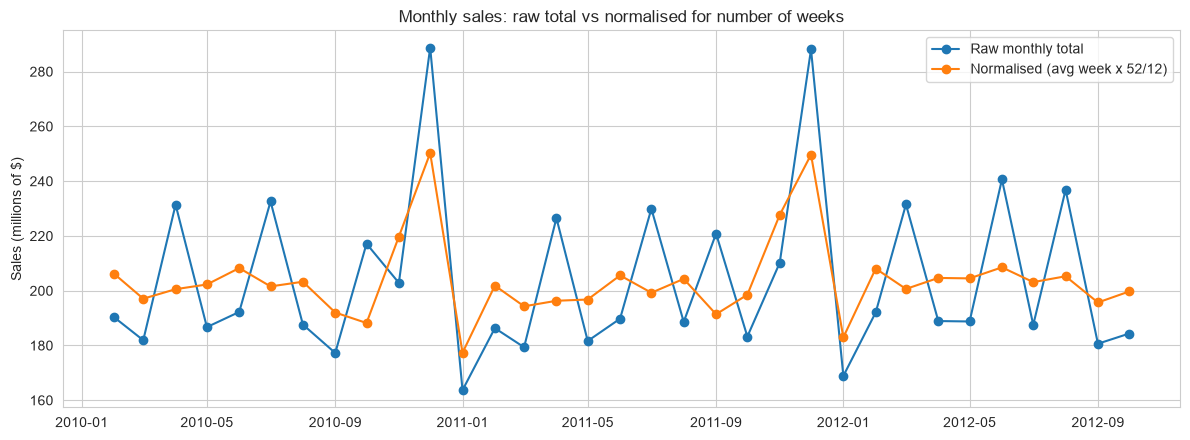

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly["month_start"], monthly["total_sales"] / 1e6, marker="o", label="Raw monthly total")
ax.plot(monthly["month_start"], monthly["monthly_equiv"] / 1e6, marker="o", label="Normalised (avg week x 52/12)")
ax.set_ylabel("Sales (millions of $)")
ax.set_title("Monthly sales: raw total vs normalised for number of weeks")
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
weekly_total = df.groupby("Date")["Weekly_Sales"].sum().rename("total_sales").reset_index()
weekly_total.to_csv("data/weekly_total_sales.csv", index=False)

monthly.drop(columns="Month").to_csv("data/monthly_sales.csv", index=False)
print("saved")

saved


In [8]:
m = monthly.set_index("month_start").copy()
m["ma3"] = m["monthly_equiv"].rolling(3).mean()                     # trailing
m["ma12"] = m["monthly_equiv"].rolling(12, center=True).mean()      # centered
m["yoy_pct"] = m["monthly_equiv"].pct_change(12) * 100

print(m[["monthly_equiv", "ma3", "ma12", "yoy_pct"]].round(0).head(8))
print("points with a 12-month MA:", m["ma12"].notna().sum())

             monthly_equiv          ma3         ma12  yoy_pct
month_start                                                  
2010-02-01     206194065.0          NaN          NaN      NaN
2010-03-01     197079786.0          NaN          NaN      NaN
2010-04-01     200557386.0  201277079.0          NaN      NaN
2010-05-01     202270179.0  199969117.0          NaN      NaN
2010-06-01     208266687.0  203698084.0          NaN      NaN
2010-07-01     201569443.0  204035436.0          NaN      NaN
2010-08-01     203276787.0  204370972.0  203902031.0      NaN
2010-09-01     192040221.0  198962150.0  203540771.0      NaN
points with a 12-month MA: 22


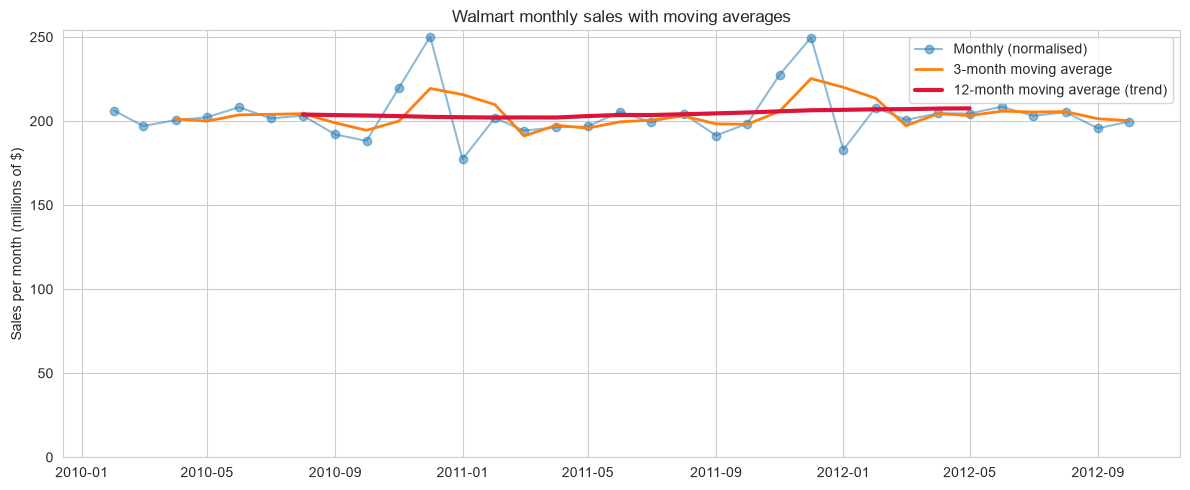

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(m.index, m["monthly_equiv"] / 1e6, alpha=0.5, marker="o", label="Monthly (normalised)")
ax.plot(m.index, m["ma3"] / 1e6, linewidth=2, label="3-month moving average")
ax.plot(m.index, m["ma12"] / 1e6, linewidth=3, color="crimson", label="12-month moving average (trend)")
ax.set_ylim(bottom=0)
ax.set_ylabel("Sales per month (millions of $)")
ax.set_title("Walmart monthly sales with moving averages")
ax.legend()
plt.tight_layout()
plt.savefig("images/trend_moving_average.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
fair = m[m.index.month.isin(range(2, 11))]
yearly = fair.groupby(fair.index.year)["monthly_equiv"].mean()
print((yearly / 1e6).round(1))
print((yearly.pct_change() * 100).round(1))

month_start
2010    199.9
2011    198.7
2012    203.4
Name: monthly_equiv, dtype: float64
month_start
2010    NaN
2011   -0.6
2012    2.3
Name: monthly_equiv, dtype: float64


In [11]:
print(m["yoy_pct"].dropna().round(1))
print("average YoY change:", round(m["yoy_pct"].mean(), 1), "%")

month_start
2011-02-01   -2.1
2011-03-01   -1.4
2011-04-01   -2.1
2011-05-01   -2.7
2011-06-01   -1.3
2011-07-01   -1.1
2011-08-01    0.5
2011-09-01   -0.3
2011-10-01    5.5
2011-11-01    3.6
2011-12-01   -0.2
2012-01-01    3.2
2012-02-01    3.1
2012-03-01    3.3
2012-04-01    4.2
2012-05-01    3.9
2012-06-01    1.4
2012-07-01    1.9
2012-08-01    0.5
2012-09-01    2.2
2012-10-01    0.6
Name: yoy_pct, dtype: float64
average YoY change: 1.1 %


In [12]:
m["month_num"] = m.index.month

prof = m.groupby("month_num")["monthly_equiv"].agg(["mean", "count"])
prof["index_simple"] = prof["mean"] / m["monthly_equiv"].mean() * 100

m["ratio_ma"] = m["monthly_equiv"] / m["ma12"] * 100
prof["index_vs_trend"] = m.groupby("month_num")["ratio_ma"].mean()
prof["n_trend"] = m.groupby("month_num")["ratio_ma"].count()
prof.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

print(prof[["count", "index_simple", "index_vs_trend", "n_trend"]].round(1))

     count  index_simple  index_vs_trend  n_trend
Jan      2          88.4            88.1        2
Feb      3         100.8           100.2        2
Mar      3          96.8            96.5        2
Apr      3          98.4            97.9        2
May      3          98.7            97.7        2
Jun      3         101.8           101.0        1
Jul      3          98.8            97.9        1
Aug      3         100.2            99.9        2
Sep      3          94.7            94.0        2
Oct      3          95.9            94.7        2
Nov      2         109.8           109.5        2
Dec      2         122.6           122.3        2


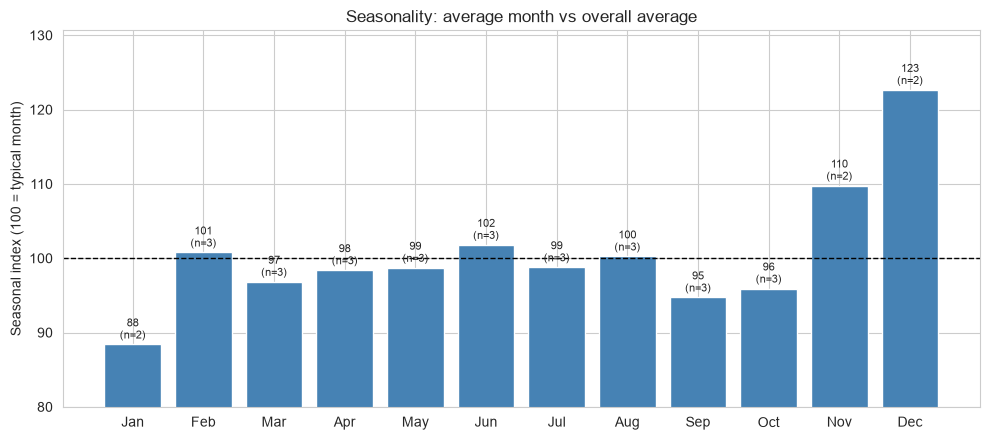

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(prof.index, prof["index_simple"], color="steelblue")
ax.axhline(100, color="black", linestyle="--", linewidth=1)
ax.set_ylim(80, prof["index_simple"].max() + 8)
ax.set_ylabel("Seasonal index (100 = typical month)")
ax.set_title("Seasonality: average month vs overall average")
for i, (idx, n) in enumerate(zip(prof["index_simple"], prof["count"])):
    ax.text(i, idx + 0.8, f"{idx:.0f}\n(n={n})", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("images/seasonal_index.png", dpi=150, bbox_inches="tight")
plt.show()

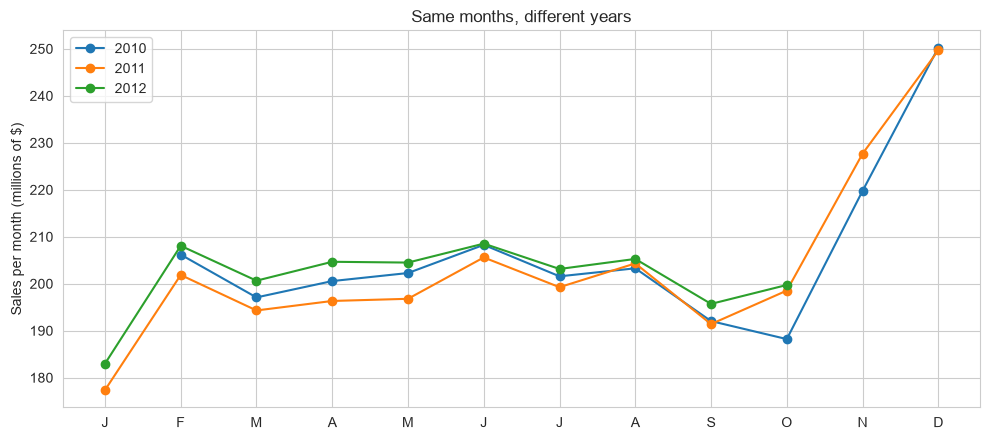

In [14]:
pivot = m.pivot_table(index="month_num", columns=m.index.year, values="monthly_equiv") / 1e6

fig, ax = plt.subplots(figsize=(10, 4.5))
for yr in pivot.columns:
    ax.plot(pivot.index, pivot[yr], marker="o", label=str(yr))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_ylabel("Sales per month (millions of $)")
ax.set_title("Same months, different years")
ax.legend()
plt.tight_layout()
plt.savefig("images/seasonal_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
w = (df.groupby("Date").agg(total=("Weekly_Sales", "sum"), holiday=("IsHoliday", "max"))
       .sort_index())

# compare each week with the average of the 2 weeks before and 2 after
neighbors = (w["total"].shift(1) + w["total"].shift(2) + w["total"].shift(-1) + w["total"].shift(-2)) / 4
w["vs_neighbors_pct"] = (w["total"] / neighbors - 1) * 100
w["rank"] = w["total"].rank(ascending=False).astype(int)

print("Flagged holiday weeks:")
print(w[w["holiday"]][["total", "vs_neighbors_pct", "rank"]].round(1))

print("\nTop 8 weeks overall (is each one flagged as a holiday?):")
print(w.sort_values("total", ascending=False).head(8)[["total", "holiday", "rank"]])

print("\nAverage weekly total, holiday vs non-holiday:")
print(w.groupby("holiday")["total"].mean().round(0))

Flagged holiday weeks:
                 total  vs_neighbors_pct  rank
Date                                          
2010-02-12  48336677.6               NaN    27
2010-09-10  45634397.8               2.8    88
2010-11-26  65821003.2              33.8     4
2010-12-31  40432519.0             -28.5   141
2011-02-11  47336192.8               6.0    51
2011-09-09  46763227.5               4.3    65
2011-11-25  66593605.3              33.3     3
2011-12-30  46042461.0             -17.8    79
2012-02-10  50009407.9              10.0    14
2012-09-07  48330059.3               5.5    28

Top 8 weeks overall (is each one flagged as a holiday?):
                  total  holiday  rank
Date                                  
2010-12-24  80931415.60    False     1
2011-12-23  76998241.31    False     2
2011-11-25  66593605.26     True     3
2010-11-26  65821003.24     True     4
2010-12-17  61820799.85    False     5
2011-12-16  60085695.94    False     6
2010-12-10  55666770.39    False     7
2011

In [17]:
dept = df.groupby("Dept")["Weekly_Sales"].sum().sort_values(ascending=False)
share = dept / dept.sum() * 100
top = pd.DataFrame({"revenue_M": (dept / 1e6).round(1),
                    "share_pct": share.round(1),
                    "cum_share_pct": share.cumsum().round(1)})
print(top.head(10))
print("departments needed for 80% of sales:", int((share.cumsum() < 80).sum() + 1), "of", len(dept))

      revenue_M  share_pct  cum_share_pct
Dept                                     
92        483.9        7.2            7.2
95        449.3        6.7           13.9
38        393.1        5.8           19.7
72        305.7        4.5           24.2
90        291.1        4.3           28.5
40        288.9        4.3           32.8
2         280.6        4.2           37.0
91        216.8        3.2           40.2
13        197.3        2.9           43.1
8         194.3        2.9           46.0
departments needed for 80% of sales: 29 of 81


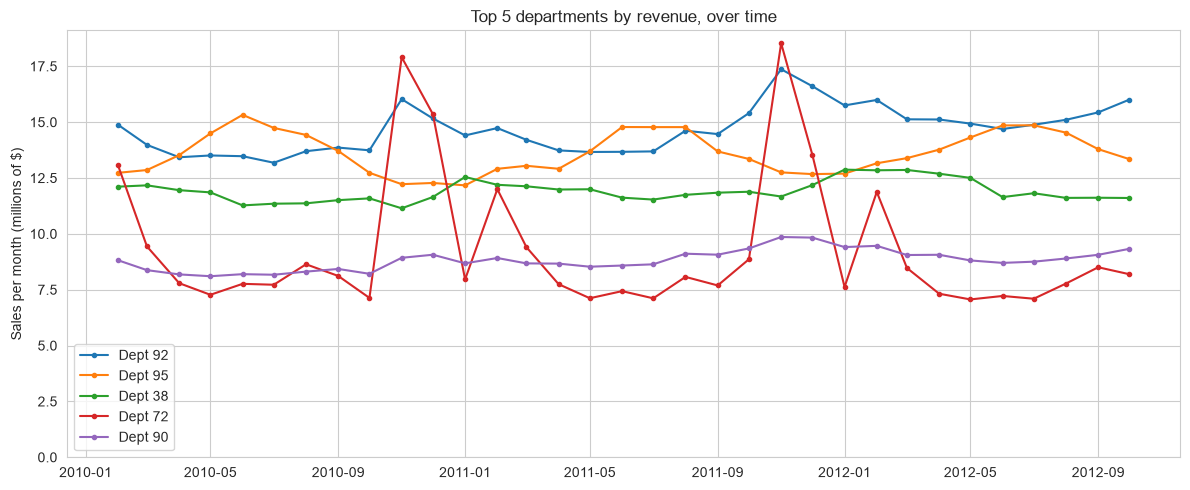

Dept      92     95     38     72     90
Month                                   
1      102.0   92.0  107.0   81.0  102.0
2      103.0   96.0  104.0  128.0  102.0
3       98.0   97.0  104.0   94.0   98.0
4       95.0   99.0  102.0   79.0   97.0
5       95.0  105.0  102.0   74.0   96.0
6       94.0  111.0   97.0   77.0   96.0
7       94.0  109.0   97.0   76.0   96.0
8       98.0  108.0   97.0   85.0   99.0
9       99.0  102.0   98.0   84.0  100.0
10     102.0   97.0   98.0   84.0  101.0
11     113.0   92.0   96.0  189.0  106.0
12     107.0   92.0  100.0  150.0  107.0


In [18]:
nweeks = monthly.set_index("Month")["n_weeks"]
dm = df.groupby(["Month", "Dept"])["Weekly_Sales"].sum().unstack("Dept")
dm_equiv = dm.div(nweeks, axis=0) * 52 / 12
dm_equiv.index = dm_equiv.index.to_timestamp()
top5 = list(top.index[:5])

fig, ax = plt.subplots(figsize=(12, 5))
for d in top5:
    ax.plot(dm_equiv.index, dm_equiv[d] / 1e6, marker="o", markersize=3, label=f"Dept {d}")
ax.set_ylim(bottom=0)
ax.set_ylabel("Sales per month (millions of $)")
ax.set_title("Top 5 departments by revenue, over time")
ax.legend()
plt.tight_layout()
plt.savefig("images/top5_departments.png", dpi=150, bbox_inches="tight")
plt.show()

# do departments peak in different months?
seas = dm_equiv[top5].groupby(dm_equiv.index.month).mean()
print((seas / seas.mean() * 100).round(0))

In [19]:
s11 = df[(df["Date"] >= "2011-02-01") & (df["Date"] <= "2011-10-31")].groupby("Dept")["Weekly_Sales"].sum()
s12 = df[(df["Date"] >= "2012-02-01") & (df["Date"] <= "2012-10-31")].groupby("Dept")["Weekly_Sales"].sum()
g = pd.DataFrame({"sales_2011": s11, "sales_2012": s12}).dropna()
g["change_pct"] = (g["sales_2012"] / g["sales_2011"] - 1) * 100

big15 = g.loc[top.index[:15]]
print((big15["change_pct"].round(1)).sort_values())
print("\nall departments, total change:",
      round((g["sales_2012"].sum() / g["sales_2011"].sum() - 1) * 100, 1), "%")

Dept
72   -2.1
94   -0.3
91    1.3
13    1.4
95    1.8
90    1.9
79    1.9
38    2.1
2     2.2
7     2.6
4     2.9
8     3.2
93    4.3
40    4.7
92    7.1
Name: change_pct, dtype: float64

all departments, total change: 2.5 %


share of total revenue by type (%):
Type
A    64.3
B    29.7
C     6.0
dtype: float64

average monthly sales per store (millions):
Type
A    5.96
B    3.56
C    2.05
dtype: float64

share of revenue in the first and last month (%):
Type        A     B    C
Month                   
2010-02  64.2  30.0  5.9
2012-10  64.4  29.3  6.4


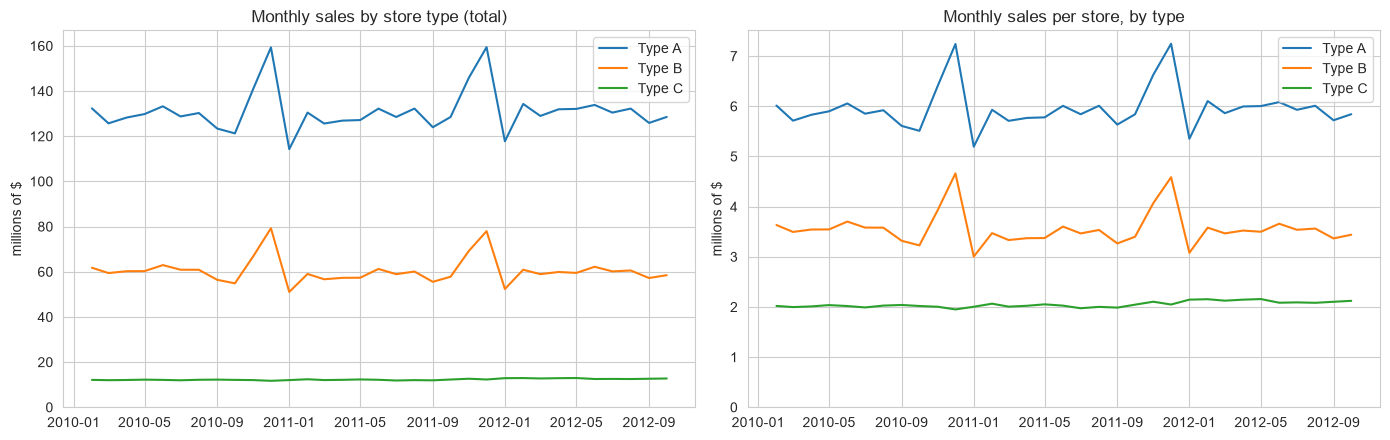

In [20]:
tm = df.groupby(["Month", "Type"])["Weekly_Sales"].sum().unstack("Type")
tm_equiv = tm.div(nweeks, axis=0) * 52 / 12
n_by_type = stores["Type"].value_counts()
per_store = tm_equiv.div(n_by_type, axis=1)
share_type = tm_equiv.div(tm_equiv.sum(axis=1), axis=0) * 100
tm_equiv.index = tm_equiv.index.to_timestamp()
per_store.index = tm_equiv.index

print("share of total revenue by type (%):")
print((tm.sum() / tm.sum().sum() * 100).round(1))
print("\naverage monthly sales per store (millions):")
print((per_store.mean() / 1e6).round(2))
print("\nshare of revenue in the first and last month (%):")
print(share_type.iloc[[0, -1]].round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for t in tm_equiv.columns:
    axes[0].plot(tm_equiv.index, tm_equiv[t] / 1e6, label=f"Type {t}")
    axes[1].plot(per_store.index, per_store[t] / 1e6, label=f"Type {t}")
axes[0].set_title("Monthly sales by store type (total)")
axes[1].set_title("Monthly sales per store, by type")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_ylabel("millions of $")
    ax.legend()
plt.tight_layout()
plt.savefig("images/store_types.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
st = df.groupby("Store")["Weekly_Sales"].sum().sort_values(ascending=False)
print("top 5 stores share:", round(st.head(5).sum() / st.sum() * 100, 1), "%")
print("bottom 5 stores share:", round(st.tail(5).sum() / st.sum() * 100, 1), "%")
print((st.head(5) / 1e6).round(1))
print(stores.set_index("Store").loc[st.head(5).index])

top 5 stores share: 21.5 %
bottom 5 stores share: 3.5 %
Store
20    301.4
4     299.5
14    289.0
13    286.5
2     275.4
Name: Weekly_Sales, dtype: float64
      Type    Size
Store             
20       A  203742
4        A  205863
14       A  200898
13       A  219622
2        A  202307


In [22]:
ts = m["monthly_equiv"]
test_n = 12
train, test = ts.iloc[:-test_n], ts.iloc[-test_n:]
print(len(train), len(test), train.index[-1].date(), "->", test.index[0].date(), "to", test.index[-1].date())

21 12 2011-10-01 -> 2011-11-01 to 2012-10-01


In [23]:
def mape(actual, pred):
    return float((np.abs(actual - pred) / actual).mean() * 100)

# seasonal indices from TRAINING months only
idx = train.groupby(train.index.month).mean() / train.mean()
test_idx = pd.Series(test.index.month, index=test.index).map(idx)

fc = pd.DataFrame({"actual": test})
fc["naive_last"] = train.iloc[-1]
fc["rolling_mean_3"] = train.iloc[-3:].mean()
fc["seasonal_naive"] = ts.shift(12).reindex(test.index)
fc["level_x_season"] = train.iloc[-12:].mean() * test_idx

deseason = train / pd.Series(train.index.month, index=train.index).map(idx)
level = deseason.ewm(alpha=0.3, adjust=False).mean().iloc[-1]
fc["exp_smooth_x_season"] = level * test_idx

methods = [c for c in fc.columns if c != "actual"]
scores = pd.Series({c: mape(fc["actual"], fc[c]) for c in methods}).sort_values()
print("MAPE (%), best first:")
print(scores.round(1))
print((fc / 1e6).round(1))

MAPE (%), best first:
level_x_season         1.5
exp_smooth_x_season    1.6
seasonal_naive         2.3
naive_last             5.5
rolling_mean_3         5.6
dtype: float64
             actual  naive_last  rolling_mean_3  seasonal_naive  \
month_start                                                       
2011-11-01    227.7       198.5           198.1           219.8   
2011-12-01    249.7       198.5           198.1           250.3   
2012-01-01    183.0       198.5           198.1           177.3   
2012-02-01    208.1       198.5           198.1           201.9   
2012-03-01    200.6       198.5           198.1           194.3   
2012-04-01    204.7       198.5           198.1           196.3   
2012-05-01    204.5       198.5           198.1           196.8   
2012-06-01    208.5       198.5           198.1           205.6   
2012-07-01    203.1       198.5           198.1           199.3   
2012-08-01    205.3       198.5           198.1           204.3   
2012-09-01    195.7     

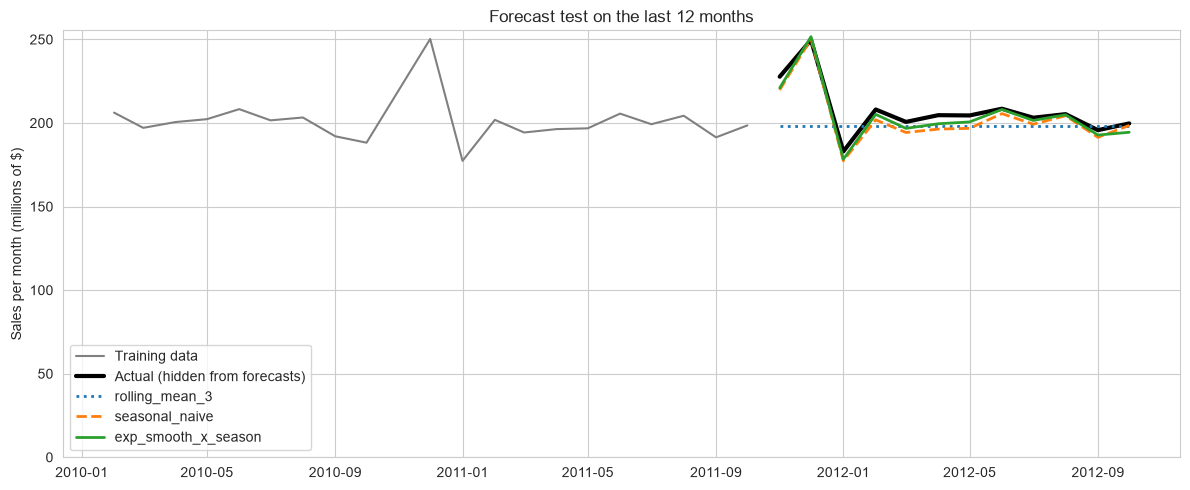

In [24]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index, train / 1e6, color="gray", label="Training data")
ax.plot(test.index, test / 1e6, color="black", linewidth=3, label="Actual (hidden from forecasts)")
for c, style in [("rolling_mean_3", ":"), ("seasonal_naive", "--"), ("exp_smooth_x_season", "-")]:
    ax.plot(fc.index, fc[c] / 1e6, style, linewidth=2, label=c)
ax.set_ylim(bottom=0)
ax.set_ylabel("Sales per month (millions of $)")
ax.set_title("Forecast test on the last 12 months")
ax.legend()
plt.tight_layout()
plt.savefig("images/forecast_backtest.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
idx_all = ts.groupby(ts.index.month).mean() / ts.mean()
deseason_all = ts / pd.Series(ts.index.month, index=ts.index).map(idx_all)
level_all = deseason_all.ewm(alpha=0.3, adjust=False).mean().iloc[-1]

future = pd.date_range(ts.index[-1] + pd.offsets.MonthBegin(1), periods=3, freq="MS")
future_fc = pd.Series([level_all * idx_all[d.month] for d in future], index=future)
last_year = ts.reindex([d - pd.DateOffset(years=1) for d in future])

print("Projection (millions):", (future_fc / 1e6).round(1).to_dict())
print("Same months last year:", (last_year / 1e6).round(1).values)

Projection (millions): {Timestamp('2012-11-01 00:00:00'): 226.8, Timestamp('2012-12-01 00:00:00'): 253.4, Timestamp('2013-01-01 00:00:00'): 182.7}
Same months last year: [227.7 249.7 183. ]


In [26]:
fc.round(0).to_csv("data/forecast_backtest.csv")
scores.rename("MAPE_pct").round(2).to_csv("data/forecast_scores.csv")
print("saved")

saved
